# InceptionTime — ECG Multi-Label Classification

**Architecture:** InceptionTime — an ensemble of Inception modules with multi-scale 1D convolutions  
**Reference:** Fawaz et al., *"InceptionTime: Finding AlexNet for Time Series Classification"* (2020)

**Key ideas:**
- Parallel Conv1D branches with different kernel sizes (10, 20, 40) capture patterns at multiple temporal scales
- Bottleneck 1×1 convolutions reduce parameters before inception modules
- Residual connections every 3 inception blocks for gradient flow
- Ensemble of 5 networks (optional) for robust final predictions

**Data:** Preprocessed arrays from `preprocessing.ipynb` (PTB-XL + PTB-XL+ ECGDeli features)  
**Runtime:** GPU recommended

## 1. Setup & Mount Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import numpy as np
import os
import json
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, callbacks
from sklearn.metrics import classification_report, roc_auc_score, f1_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore")

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")

# Reproducibility
tf.random.set_seed(42)
np.random.seed(42)

TensorFlow version: 2.19.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load Preprocessed Data

In [5]:
drive_path = 'drive/MyDrive/ECG'
data_dir = os.path.join(drive_path, "preprocessed")

with open(os.path.join(data_dir, "metadata.json"), "r") as f:
    meta = json.load(f)

SUPERCLASSES = meta["superclasses"]
SIGNAL_SHAPE = tuple(meta["signal_shape"])
N_FEATURES = meta["n_features"]
LEAD_NAMES = meta["lead_names"]

X_train = np.load(os.path.join(data_dir, "X_train.npy"))
X_val   = np.load(os.path.join(data_dir, "X_val.npy"))
X_test  = np.load(os.path.join(data_dir, "X_test.npy"))
Y_train = np.load(os.path.join(data_dir, "Y_train.npy"))
Y_val   = np.load(os.path.join(data_dir, "Y_val.npy"))
Y_test  = np.load(os.path.join(data_dir, "Y_test.npy"))
F_train = np.load(os.path.join(data_dir, "F_train.npy"))
F_val   = np.load(os.path.join(data_dir, "F_val.npy"))
F_test  = np.load(os.path.join(data_dir, "F_test.npy"))

print(f"Signal shape: {SIGNAL_SHAPE}, Features: {N_FEATURES}")
print(f"Train: {X_train.shape[0]:>6} | Val: {X_val.shape[0]:>5} | Test: {X_test.shape[0]:>5}")
print(f"Superclasses: {SUPERCLASSES}")
print(f"\nLabel distribution (train):")
for i, sc in enumerate(SUPERCLASSES):
    print(f"  {sc}: {int(Y_train[:, i].sum())}")

Signal shape: (1000, 12), Features: 531
Train:  17418 | Val:  2183 | Test:  2198
Superclasses: ['NORM', 'MI', 'STTC', 'CD', 'HYP']

Label distribution (train):
  NORM: 7596
  MI: 4379
  STTC: 4087
  CD: 3907
  HYP: 2119


In [6]:
# ── Per-class weights (inverse frequency) ──
n_samples = Y_train.shape[0]
pos_counts = Y_train.sum(axis=0)
neg_counts = n_samples - pos_counts
class_weights = neg_counts / (pos_counts + 1e-7)

print("Class imbalance analysis:")
for i, sc in enumerate(SUPERCLASSES):
    pct = pos_counts[i] / n_samples * 100
    print(f"  {sc:<8} Pos: {int(pos_counts[i]):>5}  Weight: {class_weights[i]:.2f}")

class_weights_tensor = tf.constant(class_weights, dtype=tf.float32)

Class imbalance analysis:
  NORM     Pos:  7596  Weight: 1.29
  MI       Pos:  4379  Weight: 2.98
  STTC     Pos:  4087  Weight: 3.26
  CD       Pos:  3907  Weight: 3.46
  HYP      Pos:  2119  Weight: 7.22


In [7]:
# ── FFT Bandpass Filter (0.5–40 Hz) ──
def fft_bandpass_filter(X, fs=100, low=0.5, high=40.0):
    N_samples, T, L = X.shape
    freqs = np.fft.rfftfreq(T, d=1.0/fs)
    mask = np.ones(len(freqs), dtype=np.float32)
    mask[freqs < low]  = 0.0
    mask[freqs > high] = 0.0
    transition_width = 0.5
    for i, f in enumerate(freqs):
        if low <= f < low + transition_width:
            mask[i] = (f - low) / transition_width
        elif high - transition_width < f <= high:
            mask[i] = (high - f) / transition_width
    X_filtered = np.zeros_like(X)
    for lead in range(L):
        fft_data = np.fft.rfft(X[:, :, lead], axis=1)
        fft_data *= mask[np.newaxis, :]
        X_filtered[:, :, lead] = np.fft.irfft(fft_data, n=T, axis=1)
    return X_filtered.astype(np.float32)

print("Applying FFT bandpass filter (0.5–40 Hz)...")
X_train = fft_bandpass_filter(X_train)
X_val   = fft_bandpass_filter(X_val)
X_test  = fft_bandpass_filter(X_test)
print(f"✓ Artifact suppression complete")

Applying FFT bandpass filter (0.5–40 Hz)...
✓ Artifact suppression complete


In [8]:
# ── ECG Augmentation Layer (same as ResNet notebook) ──
class ECGAugmentation(layers.Layer):
    def __init__(self, mask_ratio=0.2, mask_prob=0.8, lead_mask_prob=0.3,
                 noise_std=0.05, **kwargs):
        super().__init__(**kwargs)
        self.mask_ratio = mask_ratio
        self.mask_prob = mask_prob
        self.lead_mask_prob = lead_mask_prob
        self.noise_std = noise_std

    def call(self, inputs, training=None):
        if not training:
            return inputs
        x = inputs
        batch_size = tf.shape(x)[0]
        timesteps = tf.shape(x)[1]
        n_leads = tf.shape(x)[2]

        # Time masking
        apply_mask = tf.random.uniform([batch_size, 1, 1]) < self.mask_prob
        mask_len = tf.cast(tf.cast(timesteps, tf.float32) * self.mask_ratio, tf.int32)
        max_start = timesteps - mask_len
        starts = tf.cast(tf.random.uniform([batch_size], 0, tf.cast(max_start, tf.float32)), tf.int32)
        time_range = tf.range(timesteps)[tf.newaxis, :, tf.newaxis]
        starts_exp = starts[:, tf.newaxis, tf.newaxis]
        ends_exp = starts_exp + mask_len
        time_mask = tf.cast((time_range >= starts_exp) & (time_range < ends_exp), tf.float32)
        time_mask = time_mask * tf.cast(apply_mask, tf.float32)
        x = x * (1.0 - time_mask)

        # Lead masking
        lead_mask = tf.cast(tf.random.uniform([batch_size, 1, n_leads]) < self.lead_mask_prob, tf.float32)
        lead_mask = lead_mask * tf.cast(
            tf.reduce_sum(lead_mask, axis=-1, keepdims=True) < tf.cast(n_leads // 2, tf.float32), tf.float32)
        x = x * (1.0 - lead_mask)

        # Gaussian noise
        x = x + tf.random.normal(tf.shape(x), stddev=self.noise_std)
        return x

    def get_config(self):
        config = super().get_config()
        config.update({"mask_ratio": self.mask_ratio, "mask_prob": self.mask_prob,
                       "lead_mask_prob": self.lead_mask_prob, "noise_std": self.noise_std})
        return config

print("✓ ECGAugmentation layer defined")

✓ ECGAugmentation layer defined


## 3. InceptionTime Architecture

Each **Inception module** applies parallel Conv1D operations with different kernel sizes (10, 20, 40) plus a MaxPool branch, all preceded by a 1×1 bottleneck convolution. A residual shortcut is added every 3 modules.

```
Input (1000, 12)
  ├─ ECGAugmentation (training only)
  ├─ Inception Module ×2 (32 filters)
  ├─ Residual shortcut
  ├─ Inception Module ×2 (64 filters)
  ├─ Residual shortcut
  ├─ Inception Module ×2 (128 filters)
  ├─ Residual shortcut
  └─ GAP → Dropout → Feature fusion → Dense → 5 sigmoid
```

In [9]:
# ── InceptionTime Building Blocks ──

def inception_module(x, n_filters=32, bottleneck_size=32, kernel_sizes=[10, 20, 40]):
    """
    Single Inception module for 1D time series.
    Parallel convolutions at multiple scales + MaxPool branch.
    """
    # Bottleneck: reduce channels before expensive convolutions
    bottleneck = layers.Conv1D(bottleneck_size, 1, padding="same", use_bias=False,
                               kernel_initializer="he_normal")(x)
    bottleneck = layers.BatchNormalization()(bottleneck)
    bottleneck = layers.ReLU()(bottleneck)

    # Parallel Conv1D branches at different kernel sizes
    conv_branches = []
    for ks in kernel_sizes:
        branch = layers.Conv1D(n_filters, ks, padding="same", use_bias=False,
                               kernel_initializer="he_normal")(bottleneck)
        conv_branches.append(branch)

    # MaxPool branch (operates on original input, not bottleneck)
    pool_branch = layers.MaxPooling1D(3, strides=1, padding="same")(x)
    pool_branch = layers.Conv1D(n_filters, 1, padding="same", use_bias=False,
                                kernel_initializer="he_normal")(pool_branch)
    conv_branches.append(pool_branch)

    # Concatenate all branches
    out = layers.Concatenate(axis=-1)(conv_branches)  # (T, n_filters * 4)
    out = layers.BatchNormalization()(out)
    out = layers.ReLU()(out)
    return out


def inception_residual_block(x, n_filters=32, bottleneck_size=32, n_modules=3):
    """
    Stack of Inception modules with a residual shortcut across the block.
    """
    shortcut = x
    for _ in range(n_modules):
        x = inception_module(x, n_filters=n_filters, bottleneck_size=bottleneck_size)

    # Residual shortcut — match channels
    n_out_channels = n_filters * 4  # 3 conv branches + 1 pool branch
    shortcut = layers.Conv1D(n_out_channels, 1, padding="same", use_bias=False)(shortcut)
    shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Add()([shortcut, x])
    x = layers.ReLU()(x)
    return x


def build_inception_model(signal_shape=(1000, 12), n_features=None, n_classes=5,
                          use_augmentation=True):
    """
    InceptionTime multi-input model for ECG multi-label classification.
    """
    # ── Signal Branch: InceptionTime ──
    signal_input = layers.Input(shape=signal_shape, name="signal_input")

    if use_augmentation:
        x = ECGAugmentation(mask_ratio=0.2, mask_prob=0.8,
                            lead_mask_prob=0.3, noise_std=0.05)(signal_input)
    else:
        x = signal_input

    # 3 Inception residual blocks with increasing filter sizes
    x = inception_residual_block(x, n_filters=32,  bottleneck_size=32,  n_modules=2)
    x = layers.MaxPooling1D(2)(x)  # (500, 128)

    x = inception_residual_block(x, n_filters=64,  bottleneck_size=64,  n_modules=2)
    x = layers.MaxPooling1D(2)(x)  # (250, 256)

    x = inception_residual_block(x, n_filters=128, bottleneck_size=128, n_modules=2)

    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    signal_branch = x

    # ── Feature Branch: MLP ──
    if n_features is not None and n_features > 0:
        feature_input = layers.Input(shape=(n_features,), name="feature_input")
        f = layers.Dense(128, activation="relu", kernel_initializer="he_normal")(feature_input)
        f = layers.BatchNormalization()(f)
        f = layers.Dropout(0.3)(f)
        f = layers.Dense(64, activation="relu", kernel_initializer="he_normal")(f)
        f = layers.BatchNormalization()(f)
        f = layers.Dropout(0.2)(f)
        merged = layers.Concatenate()([signal_branch, f])
        inputs = [signal_input, feature_input]
    else:
        merged = signal_branch
        inputs = [signal_input]

    # ── Classification Head ──
    merged = layers.Dense(256, activation="relu", kernel_initializer="he_normal")(merged)
    merged = layers.BatchNormalization()(merged)
    merged = layers.Dropout(0.4)(merged)
    merged = layers.Dense(128, activation="relu", kernel_initializer="he_normal")(merged)
    merged = layers.Dropout(0.3)(merged)
    output = layers.Dense(n_classes, activation="sigmoid", name="output")(merged)

    return Model(inputs=inputs, outputs=output)


model = build_inception_model(
    signal_shape=SIGNAL_SHAPE, n_features=N_FEATURES, n_classes=5,
    use_augmentation=True
)
model.summary()
print(f"\nTotal parameters: {model.count_params():,}")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ signal_input        │ (None, 1000, 12)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ecg_augmentation    │ (None, 1000, 12)  │          0 │ signal_input[0][… │
│ (ECGAugmentation)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 1000, 32)  │        384 │ ecg_augmentation… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 1000, 32)  │        128 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 1000, 32)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 1000, 12)  │          0 │ ecg_augmentation… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 1000, 32)  │     10,240 │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 1000, 32)  │     20,480 │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 1000, 32)  │     40,960 │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 1000, 32)  │        384 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 1000, 128) │          0 │ conv1d_1[0][0],   │
│ (Concatenate)       │                   │            │ conv1d_2[0][0],   │
│                     │                   │            │ conv1d_3[0][0],   │
│                     │                   │            │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1000, 128) │        512 │ concatenate[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 1000, 128) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 1000, 32)  │      4,096 │ re_lu_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1000, 32)  │        128 │ conv1d_5[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 1000, 32)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 1000, 128) │          0 │ re_lu_1[0][0]     │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 1000, 32)  │     10,240 │ re_lu_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 1000, 32)  │     20,480 │ re_lu_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 1000, 32)  │     40,960 │ re_lu_2[0][0]   

 Total params: 3,702,597 (14.12 MB)

 Trainable params: 3,695,429 (14.10 MB)

 Non-trainable params: 7,168 (28.00 KB)


Total parameters: 3,702,597


## 4. Compile & Train

In [10]:
model_save_dir = os.path.join(drive_path, "models", "inception")
os.makedirs(model_save_dir, exist_ok=True)
best_model_path = os.path.join(model_save_dir, "best_inception_model.keras")

# Weighted BCE
def weighted_bce(y_true, y_pred):
    bce = tf.keras.backend.binary_crossentropy(y_true, y_pred)
    weights = y_true * class_weights_tensor + (1.0 - y_true) * 1.0
    return tf.reduce_mean(bce * weights, axis=-1)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=weighted_bce,
    metrics=[
        keras.metrics.AUC(name="auc", multi_label=True),
        keras.metrics.F1Score(name="f1", average="macro", threshold=0.5),
    ]
)

cb = [
    callbacks.EarlyStopping(monitor="val_auc", patience=12, mode="max",
                            restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_auc", factor=0.5, patience=5,
                                mode="max", min_lr=1e-6, verbose=1),
    callbacks.ModelCheckpoint(best_model_path, monitor="val_auc",
                              mode="max", save_best_only=True, verbose=1),
]

print(f"Model compiled ✓  (weighted BCE)")
print(f"Checkpoints → {best_model_path}")

Model compiled ✓  (weighted BCE)
Checkpoints → drive/MyDrive/ECG/models/inception/best_inception_model.keras


In [11]:
BATCH_SIZE = 64
EPOCHS = 50

history = model.fit(
    [X_train, F_train], Y_train,
    validation_data=([X_val, F_val], Y_val),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=cb,
    verbose=1,
)
print("\n✓ Training complete")

Epoch 1/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - auc: 0.7507 - f1: 0.5097 - loss: 0.9949
Epoch 1: val_auc improved from -inf to 0.85509, saving model to drive/MyDrive/ECG/models/inception/best_inception_model.keras
273/273 ━━━━━━━━━━━━━━━━━━━━ 107s 253ms/step - auc: 0.7509 - f1: 0.5099 - loss: 0.9944 - val_auc: 0.8551 - val_f1: 0.5894 - val_loss: 0.7877 - learning_rate: 0.0010
Epoch 2/50
272/273 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - auc: 0.8657 - f1: 0.6233 - loss: 0.6935
Epoch 2: val_auc improved from 0.85509 to 0.89842, saving model to drive/MyDrive/ECG/models/inception/best_inception_model.keras
273/273 ━━━━━━━━━━━━━━━━━━━━ 44s 160ms/step - auc: 0.8657 - f1: 0.6234 - loss: 0.6934 - val_auc: 0.8984 - val_f1: 0.6541 - val_loss: 0.6448 - learning_rate: 0.0010
Epoch 3/50
272/273 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - auc: 0.8879 - f1: 0.6545 - loss: 0.6316
Epoch 3: val_auc improved from 0.89842 to 0.90943, saving model to drive/MyDrive/ECG/models/inception/best_inception_model.keras

## 5. Training Curves

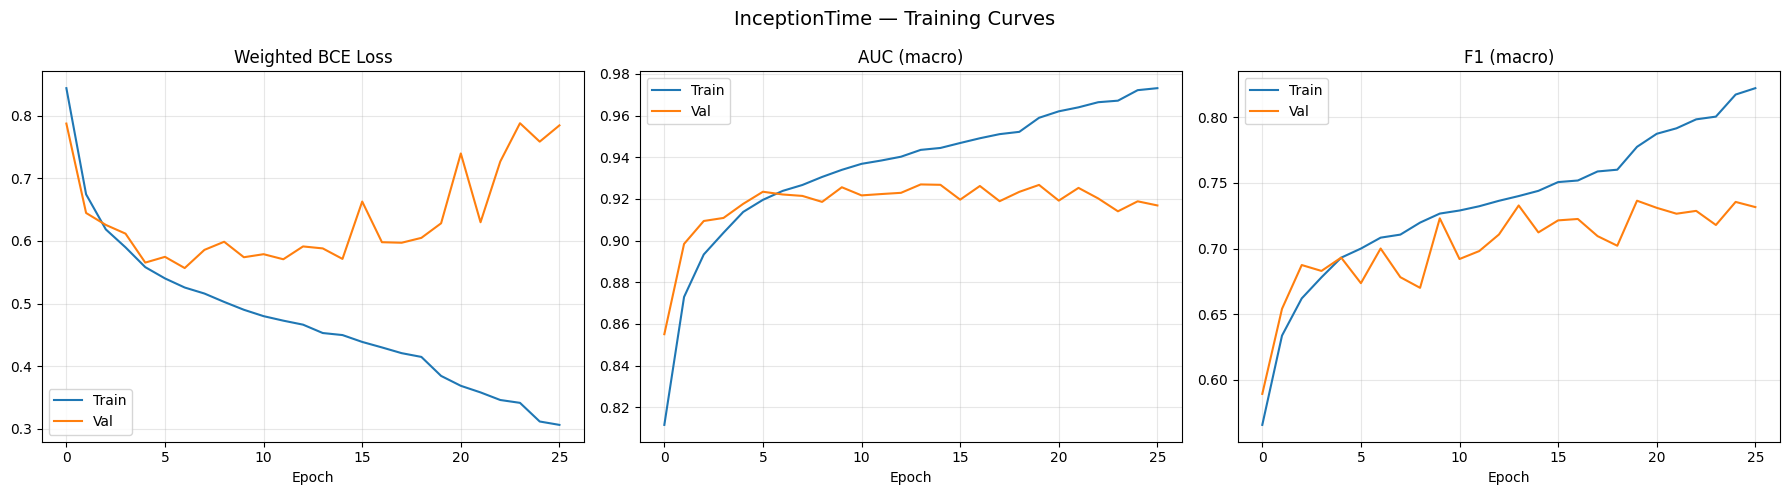

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history.history["loss"], label="Train"); axes[0].plot(history.history["val_loss"], label="Val")
axes[0].set_title("Weighted BCE Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history["auc"], label="Train"); axes[1].plot(history.history["val_auc"], label="Val")
axes[1].set_title("AUC (macro)"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].plot(history.history["f1"], label="Train"); axes[2].plot(history.history["val_f1"], label="Val")
axes[2].set_title("F1 (macro)"); axes[2].set_xlabel("Epoch"); axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.suptitle("InceptionTime — Training Curves", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(model_save_dir, "training_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

## 6. Evaluate on Test Set (Fold 10)

In [13]:
best_model = keras.models.load_model(best_model_path, custom_objects={
    "weighted_bce": weighted_bce, "ECGAugmentation": ECGAugmentation})

Y_pred_prob = best_model.predict([X_test, F_test], batch_size=64, verbose=1)
Y_pred = (Y_pred_prob >= 0.5).astype(int)

print("=" * 60)
print("PER-CLASS METRICS — InceptionTime (Test Set — Fold 10)")
print("=" * 60)

auc_scores = {}
for i, sc in enumerate(SUPERCLASSES):
    try:
        auc = roc_auc_score(Y_test[:, i], Y_pred_prob[:, i])
    except ValueError:
        auc = float("nan")
    auc_scores[sc] = auc
    print(f"  {sc:>5}: AUC = {auc:.4f}")

macro_auc = np.nanmean(list(auc_scores.values()))
print(f"\n  Macro AUC: {macro_auc:.4f}")

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(Y_test, Y_pred, target_names=SUPERCLASSES, zero_division=0))

f1_per_class = f1_score(Y_test, Y_pred, average=None, zero_division=0)
f1_macro = f1_score(Y_test, Y_pred, average="macro", zero_division=0)
print(f"Per-class F1: {dict(zip(SUPERCLASSES, [f'{f:.4f}' for f in f1_per_class]))}")
print(f"Macro F1:     {f1_macro:.4f}")

35/35 ━━━━━━━━━━━━━━━━━━━━ 7s 130ms/step
PER-CLASS METRICS — InceptionTime (Test Set — Fold 10)
   NORM: AUC = 0.9454
     MI: AUC = 0.9096
   STTC: AUC = 0.9299
     CD: AUC = 0.9181
    HYP: AUC = 0.9018

  Macro AUC: 0.9210

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        NORM       0.76      0.95      0.84       963
          MI       0.62      0.84      0.71       550
        STTC       0.71      0.80      0.75       506
          CD       0.64      0.81      0.72       496
         HYP       0.52      0.71      0.60       262

   micro avg       0.68      0.85      0.75      2777
   macro avg       0.65      0.82      0.72      2777
weighted avg       0.68      0.85      0.76      2777
 samples avg       0.73      0.84      0.76      2777

Per-class F1: {'NORM': '0.8443', 'MI': '0.7112', 'STTC': '0.7526', 'CD': '0.7169', 'HYP': '0.5958'}
Macro F1:     0.7242


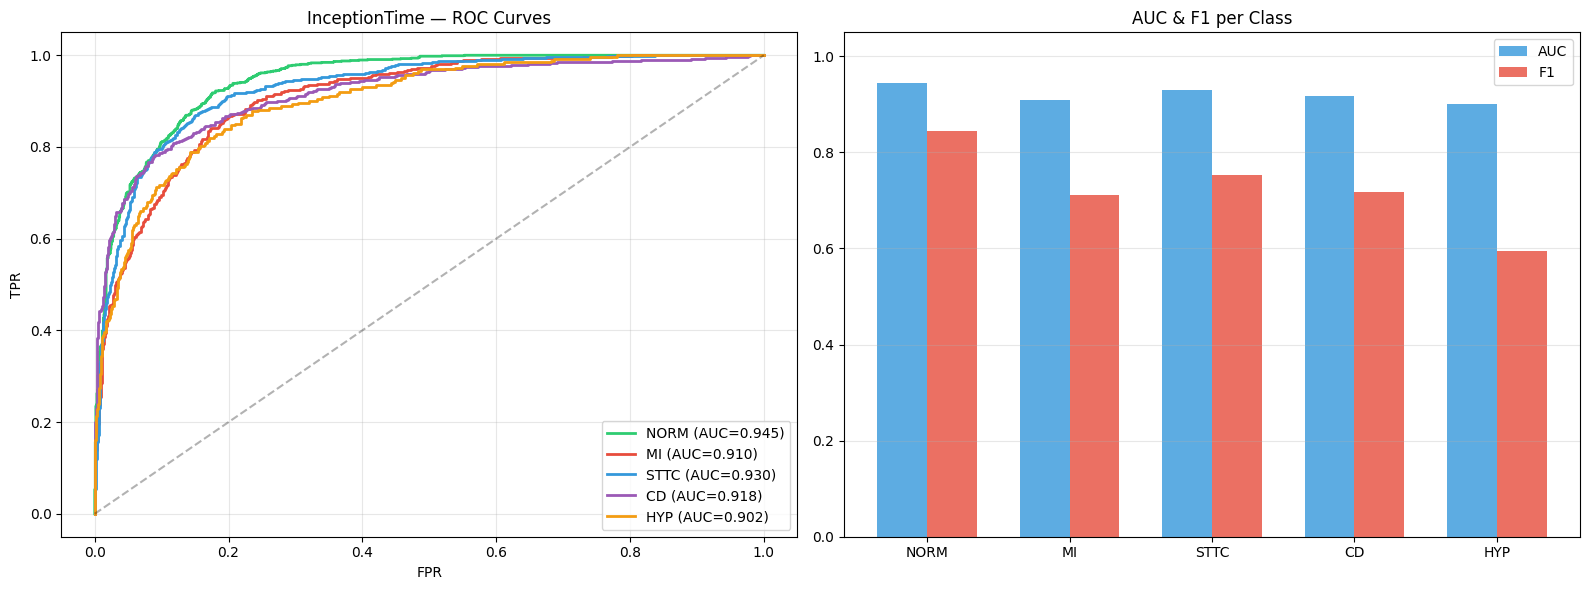

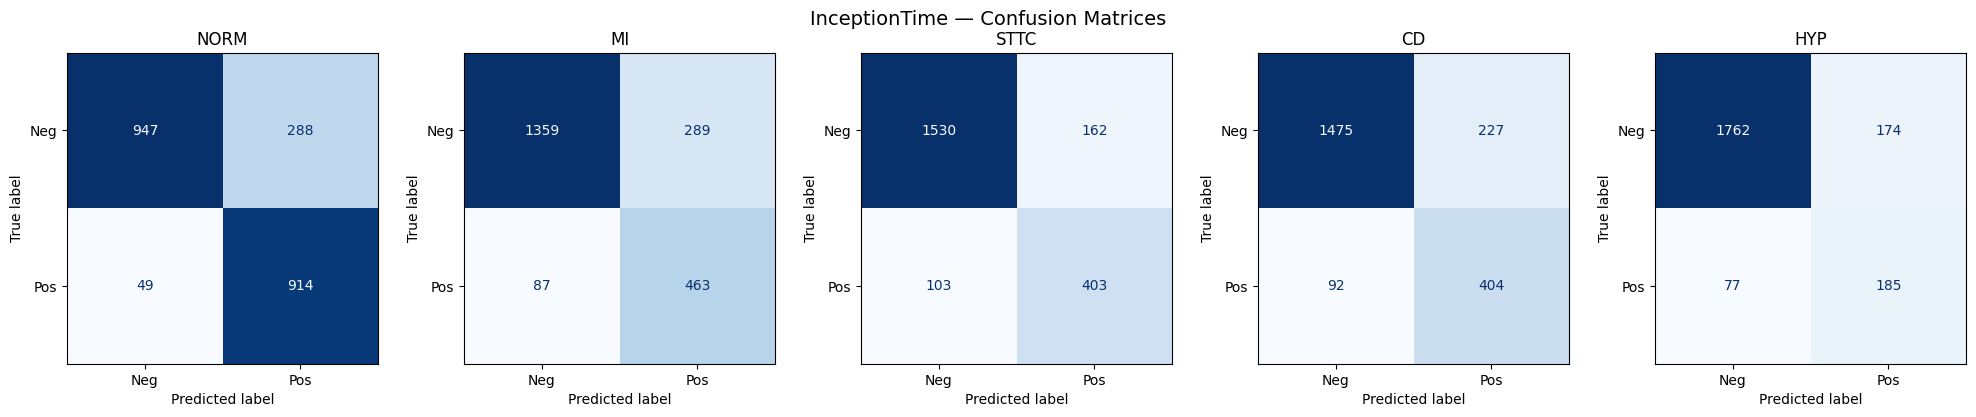

In [14]:
# ── ROC Curves & Confusion Matrices ──
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = ["#2ecc71", "#e74c3c", "#3498db", "#9b59b6", "#f39c12"]

for i, (sc, color) in enumerate(zip(SUPERCLASSES, colors)):
    fpr, tpr, _ = roc_curve(Y_test[:, i], Y_pred_prob[:, i])
    axes[0].plot(fpr, tpr, label=f"{sc} (AUC={auc_scores[sc]:.3f})", color=color, linewidth=2)
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.3)
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
axes[0].set_title("InceptionTime — ROC Curves"); axes[0].legend(loc="lower right"); axes[0].grid(True, alpha=0.3)

x_pos = np.arange(len(SUPERCLASSES)); width = 0.35
axes[1].bar(x_pos - width/2, [auc_scores[sc] for sc in SUPERCLASSES], width, label="AUC", color="#3498db", alpha=0.8)
axes[1].bar(x_pos + width/2, f1_per_class, width, label="F1", color="#e74c3c", alpha=0.8)
axes[1].set_xticks(x_pos); axes[1].set_xticklabels(SUPERCLASSES); axes[1].set_ylim(0, 1.05)
axes[1].set_title("AUC & F1 per Class"); axes[1].legend(); axes[1].grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(os.path.join(model_save_dir, "roc_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

# Confusion matrices
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i, (ax, sc) in enumerate(zip(axes, SUPERCLASSES)):
    cm = confusion_matrix(Y_test[:, i], Y_pred[:, i])
    ConfusionMatrixDisplay(cm, display_labels=["Neg", "Pos"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(sc)
plt.suptitle("InceptionTime — Confusion Matrices", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(model_save_dir, "confusion_matrices.png"), dpi=150, bbox_inches="tight")
plt.show()

## 7. TFLite Conversion

In [15]:
# Float16 quantization
converter = tf.lite.TFLiteConverter.from_keras_model(best_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
tflite_model = converter.convert()

tflite_path = os.path.join(model_save_dir, "inception_fp16.tflite")
with open(tflite_path, "wb") as f:
    f.write(tflite_model)

keras_size = os.path.getsize(best_model_path) / 1e6
tflite_size = os.path.getsize(tflite_path) / 1e6
print(f"Keras:  {keras_size:.2f} MB")
print(f"TFLite: {tflite_size:.2f} MB  ({tflite_size/keras_size*100:.1f}%)")

# Quick TFLite validation
def run_tflite_inference(tflite_path, X_signal, X_features):
    interpreter = tf.lite.Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    inp = interpreter.get_input_details()
    out = interpreter.get_output_details()
    preds = []
    for i in range(len(X_signal)):
        for d in inp:
            if "signal" in d["name"]:
                interpreter.set_tensor(d["index"], X_signal[i:i+1].astype(np.float32))
            elif "feature" in d["name"]:
                interpreter.set_tensor(d["index"], X_features[i:i+1].astype(np.float32))
        interpreter.invoke()
        preds.append(interpreter.get_tensor(out[0]["index"])[0])
    return np.array(preds)

n_eval = min(500, len(X_test))
tflite_preds = run_tflite_inference(tflite_path, X_test[:n_eval], F_test[:n_eval])
tflite_auc = roc_auc_score(Y_test[:n_eval], tflite_preds, average="macro")
tflite_f1 = f1_score(Y_test[:n_eval], (tflite_preds >= 0.5).astype(int), average="macro", zero_division=0)

print(f"\nTFLite Macro AUC: {tflite_auc:.4f}  |  Keras: {macro_auc:.4f}")
print(f"TFLite Macro F1:  {tflite_f1:.4f}  |  Keras: {f1_macro:.4f}")

Saved artifact at '/tmp/tmpx1xvh6m2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 1000, 12), dtype=tf.float32, name='signal_input'), TensorSpec(shape=(None, 531), dtype=tf.float32, name='feature_input')]
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  135378173873808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135378173875344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135378173873424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135378173876496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135378173874960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135378173875152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135378173874576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135378173876880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135378173874768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1353781738